## 1. Import Libraries
Mengimpor library yang dibutuhkan untuk komputasi numerik dan pemrosesan data (`NumPy`, `pandas`), visualisasi grafis (`matplotlib`, `seaborn`), pembacaan dan manipulasi citra (`PIL`, `glob`, `zipfile`, `tqdm`), pemisahan dataset dan evaluasi metrik (`scikit-learn`), serta perancangan arsitektur CNN dan pipeline input data (`TensorFlow`/`Keras`). Random seed diatur ke 42 untuk menjamin reproduktibilitas eksperimen.


In [1]:
import os
import zipfile
from glob import glob
from tqdm import tqdm
from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import tensorflow as tf
from tensorflow.keras.regularizers import l2

# Mengatur random seed agar hasil eksperimen konsisten dan dapat direproduksi
tf.keras.utils.set_random_seed(42)
print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.21.0


## 2. Download and Extract Dataset
Mengunduh dataset MRL Eye Dataset (`prasadvpatil/mrl-dataset`) dari Kaggle menggunakan Kaggle CLI dan mengekstrak berkas arsip `mrl-dataset.zip` ke direktori kerja (`/content/`). Dataset ini memuat ribuan citra potongan mata dalam kondisi terbuka (`Open_Eyes`) dan tertutup (`Closed_Eyes`).


In [2]:
! pip install -q kaggle
! kaggle datasets download prasadvpatil/mrl-dataset


Dataset URL: https://www.kaggle.com/datasets/prasadvpatil/mrl-dataset
License(s): CC0-1.0
100% 22.6M/22.6M [00:00<00:00, 69.3MB/s]



In [3]:
with zipfile.ZipFile('mrl-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')


## 3. Load and Preprocess Images (Data Cleaning)
Memuat setiap file citra dari direktori `train/Open_Eyes` (diberi label 1: Awake) dan `train/Closed_Eyes` (diberi label 0: Not awake).

**Tahapan Pembersihan Data (Poin 4.a):**
1. **Penanganan Citra Rusak:** Setiap berkas citra dibuka dalam blok `try-except`. Citra yang rusak (*corrupt*) atau tidak terbaca secara otomatis dilewati dan dicatat ke dalam daftar `corrupt`.
2. **Standardisasi Format dan Dimensi:** Seluruh citra dikonversi ke grayscale (`convert('L')`) untuk memastikan konsistensi satu kanal warna dan diubah ukurannya (*resize*) menjadi dimensi standar 64x64 piksel.
3. **Verifikasi Integritas:** Memastikan jumlah citra yang berhasil dimuat sesuai dan tidak ada data yang mengalami anomali dimensi.


In [4]:
PATH = '/content/train' if os.path.exists('/content/train') else './train'

X = []
Y = []
corrupt = []

# Memuat citra mata terbuka (Open_Eyes -> Label 1)
open_files = glob(os.path.join(PATH, 'Open_Eyes', '*'))
for file_path in tqdm(open_files, desc="Memuat Open Eyes"):
    try:
        img = Image.open(file_path).convert('L').resize((64, 64))
        X.append(np.array(img))
        Y.append(1)
    except Exception:
        corrupt.append(file_path)

# Memuat citra mata tertutup (Closed_Eyes -> Label 0)
closed_files = glob(os.path.join(PATH, 'Closed_Eyes', '*'))
for file_path in tqdm(closed_files, desc="Memuat Closed Eyes"):
    try:
        img = Image.open(file_path).convert('L').resize((64, 64))
        X.append(np.array(img))
        Y.append(0)
    except Exception:
        corrupt.append(file_path)

print(f"Total citra berhasil dimuat : {len(X)}")
print(f"Total citra rusak / diskip  : {len(corrupt)}")


Memuat Closed Eyes: 100%|██████████| 2000/2000 [00:00<00:00, 2643.75it/s]

Total citra berhasil dimuat : 4000
Total citra rusak / diskip  : 0


## 4. Exploratory Data Analysis (EDA) and Dataset Complexity
Pada tahapan EDA, dilakukan analisis mendalam terhadap struktur data dan karakteristik visual citra:

* **Kompleksitas Dataset (Poin 2.d):** Dataset MRL terdiri dari citra potongan mata terpusat (*tight eye crop*) berskala kecil. Tantangan utamanya adalah variasi intra-kelas yang tinggi akibat perbedaan bentuk kelopak mata, sudut pengambilan gambar, pantulan cahaya pada kacamata, dan kondisi pencahayaan inframerah. Tantangan paling kritis adalah *domain shift* ketika model diterapkan pada wajah penuh (*full face*) atau citra kamera web eksternal yang memiliki latar belakang lebih luas dan pencahayaan dinamis.
* **Distribusi Label/Kelas (Poin 3.a):** Menghitung proporsi dan rasio keseimbangan antar-kelas.
* **Karakteristik Data Citra vs Tabular/Teks (Poin 3.b, 3.c, 3.d):**
  - *Word count (3.b):* Tidak relevan karena dataset berupa citra murni, bukan korpus teks.
  - *Histogram numerik (3.c):* Sebagai padanan fitur numerik tabular, dianalisis **histogram distribusi intensitas piksel (0 - 255)** untuk memahami persebaran intensitas cahaya pada kedua kelas.
  - *Korelasi antarfitur (3.d):* Tidak berlaku karena nilai piksel citra spasial tidak direpresentasikan dalam kolom-kolom tabular independen.
* **Contoh Sampel Data per Kelas (Poin 3.e):** Menampilkan grid beberapa sampel per kelas untuk mengamati keragaman visual mata terbuka vs tertutup.
* **Temuan EDA yang Memengaruhi Preprocessing (Poin 3.f):**
  1. Citra memiliki rentang nilai piksel 0 - 255 dengan kecerahan rata-rata bimodal, sehingga operasi normalisasi piksel (rescaling $1/255$) menjadi wajib.
  2. Distribusi kelas seimbang sempurna (2.000 vs 2.000), sehingga tidak diperlukan teknik oversampling, undersampling, atau class weighting.
  3. Keragaman sudut dan pencahayaan mengindikasikan perlunya augmentasi citra yang komprehensif.


=== DISTRIBUSI KELAS DATASET (POIN 3.a) ===
  Closed Eyes (0 - Not awake) : 2000 sampel
  Open Eyes   (1 - Awake)     : 2000 sampel
  Rasio Keseimbangan          : 1.0000 (Seimbang Sempurna)

=== STATISTIK DASAR TENSOR CITRA ===
  Dimensi Tensor      : (4000, 64, 64)
  Tipe Data           : uint8
  Rentang Nilai Piksel: 0 - 255
  Rata-rata Intensitas: 93.06


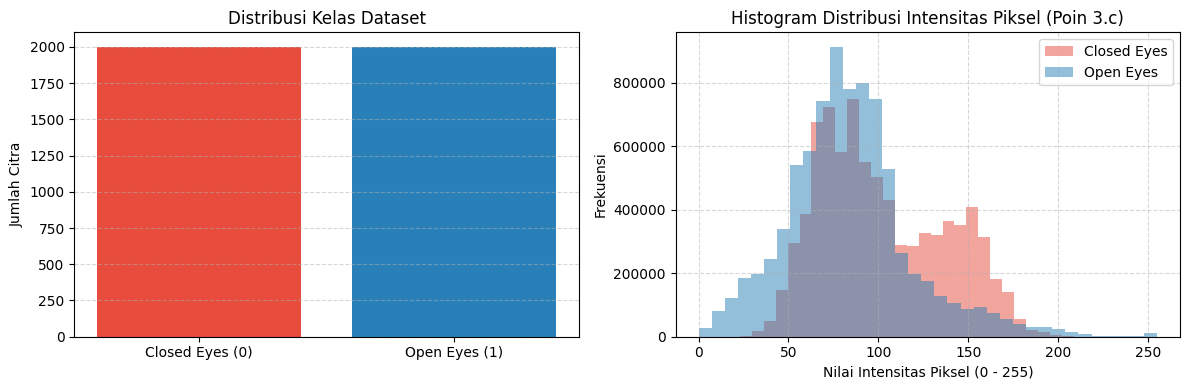

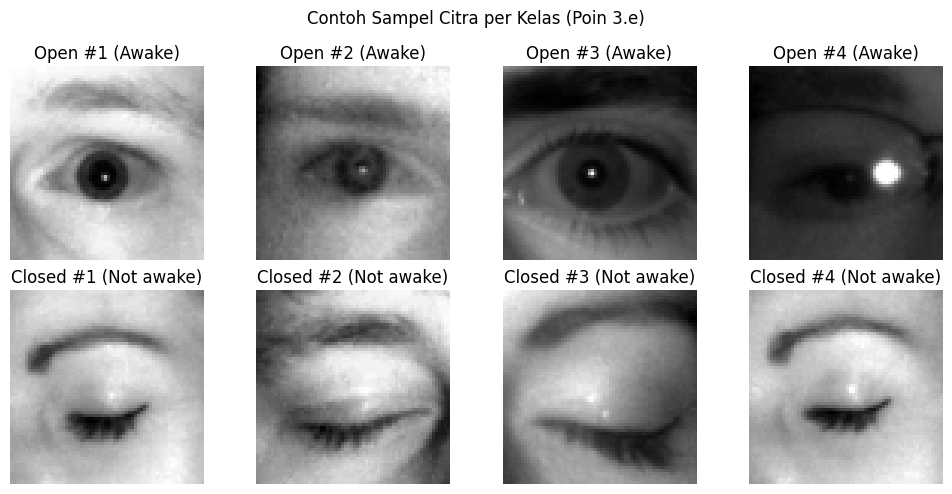

In [5]:
# Distribusi Label / Kelas
unique, counts = np.unique(Y, return_counts=True)
class_dist = dict(zip(unique, counts))
n_closed, n_open = class_dist.get(0, 0), class_dist.get(1, 0)
balance_ratio = min(n_closed, n_open) / max(n_closed, n_open)

print("=== DISTRIBUSI KELAS DATASET (POIN 3.a) ===")
print(f"  Closed Eyes (0 - Not awake) : {n_closed} sampel")
print(f"  Open Eyes   (1 - Awake)     : {n_open} sampel")
print(f"  Rasio Keseimbangan          : {balance_ratio:.4f} (Seimbang Sempurna)")

# Statistik Citra
X_arr = np.array(X)
print("\n=== STATISTIK DASAR TENSOR CITRA ===")
print("  Dimensi Tensor      :", X_arr.shape)
print("  Tipe Data           :", X_arr.dtype)
print("  Rentang Nilai Piksel:", X_arr.min(), "-", X_arr.max())
print(f"  Rata-rata Intensitas: {X_arr.mean():.2f}")

# Visualisasi 1: Distribusi Kelas & Histogram Intensitas Piksel (Poin 3.a & 3.c)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Closed Eyes (0)', 'Open Eyes (1)'], [n_closed, n_open], color=['#e74c3c', '#2980b9'])
axes[0].set_title('Distribusi Kelas Dataset')
axes[0].set_ylabel('Jumlah Citra')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].hist(X_arr[np.array(Y) == 0].ravel(), bins=35, color='#e74c3c', alpha=0.5, label='Closed Eyes')
axes[1].hist(X_arr[np.array(Y) == 1].ravel(), bins=35, color='#2980b9', alpha=0.5, label='Open Eyes')
axes[1].set_title('Histogram Distribusi Intensitas Piksel (Poin 3.c)')
axes[1].set_xlabel('Nilai Intensitas Piksel (0 - 255)')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Visualisasi 2: Grid Beberapa Sampel per Kelas (Poin 3.e)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
open_indices = np.where(np.array(Y) == 1)[0][:4]
closed_indices = np.where(np.array(Y) == 0)[0][:4]

for i, idx in enumerate(open_indices):
    axes[0, i].imshow(X[idx], cmap='gray')
    axes[0, i].set_title(f'Open #{i+1} (Awake)')
    axes[0, i].axis('off')

for i, idx in enumerate(closed_indices):
    axes[1, i].imshow(X[idx], cmap='gray')
    axes[1, i].set_title(f'Closed #{i+1} (Not awake)')
    axes[1, i].axis('off')

plt.suptitle('Contoh Sampel Citra per Kelas (Poin 3.e)', fontsize=12)
plt.tight_layout()
plt.show()


## 5. Dataset Splitting and Data Leakage Prevention
**Pembagian Data dan Proporsinya (Poin 4.e):**
Dataset dibagi menjadi tiga subset menggunakan fungsi `train_test_split` dari scikit-learn dengan parameter `stratify=Y` dan `random_state=42`:
1. **Training Set (70% - 2.800 sampel):** Digunakan untuk melatih dan mengoptimalkan parameter bobot model.
2. **Validation Set (15% - 600 sampel):** Digunakan untuk pemantauan performa saat pelatihan dan memicu mekanisme callback (*EarlyStopping* & *ReduceLROnPlateau*).
3. **Testing Set (15% - 600 sampel):** Disimpan terpisah dan tidak pernah disentuh selama pelatihan untuk pengujian akhir model tanpa bias.

**Pencegahan Kebocoran Data (Data Leakage Prevention):**
* Pemisahan data dilakukan **sebelum** proses augmentasi diterapkan.
* Augmentasi citra dirancang sebagai lapisan internal model (`In-Graph Augmentation Layer`), sehingga proses transformasi acak hanya berjalan pada subset pelatihan (`training=True`) dan secara otomatis dinonaktifkan saat mengevaluasi data validasi dan testing.


In [6]:
# Pembagian pertama: 70% Train, 30% Temporary (Validation + Test)
x_train, x_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    shuffle=True,
    stratify=Y
)

# Pembagian kedua: 50% Validation, 50% Test dari subset Temporary (masing-masing 15% dari total)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True,
    stratify=y_temp
)

print("=== PROPORSI PEMBAGIAN DATASET (POIN 4.e) ===")
print(f"  Training Set   : {len(x_train)} sampel ({len(x_train)/len(X)*100:.1f}%)")
print(f"  Validation Set : {len(x_val)} sampel ({len(x_val)/len(X)*100:.1f}%)")
print(f"  Testing Set    : {len(x_test)} sampel ({len(x_test)/len(X)*100:.1f}%)")


=== PROPORSI PEMBAGIAN DATASET (POIN 4.e) ===
  Training Set   : 2800 sampel (70.0%)
  Validation Set : 600 sampel (15.0%)
  Testing Set    : 600 sampel (15.0%)


## 6. Input Pipeline and Data Normalization
**Normalisasi dan Pipeline tf.data (Poin 4.b):**
1. Setiap subset citra diubah menjadi array NumPy berdimensi 4D `(N, 64, 64, 1)` untuk menambahkan kanal warna tunggal grayscale.
2. Pipeline input dibangun menggunakan `tf.data.Dataset` dengan batch size 32.
3. Subset pelatihan dikonfigurasi dengan `shuffle(1000, seed=42, reshuffle_each_iteration=True)` dan `prefetch(tf.data.AUTOTUNE)` untuk memaksimalkan throughput komputasi hardware.
4. Rescaling piksel dari rentang `[0, 255]` ke rentang normal `[0, 1]` disematkan sebagai lapisan awal di dalam model melalui `tf.keras.layers.Rescaling(1.0 / 255)`.


In [7]:
# Konversi ke NumPy Array 4D (N, 64, 64, 1)
x_train_arr = np.expand_dims(np.array(x_train), axis=-1).astype(np.float32)
x_val_arr   = np.expand_dims(np.array(x_val), axis=-1).astype(np.float32)
x_test_arr  = np.expand_dims(np.array(x_test), axis=-1).astype(np.float32)

y_train_arr = np.array(y_train, dtype=np.float32)
y_val_arr   = np.array(y_val, dtype=np.float32)
y_test_arr  = np.array(y_test, dtype=np.float32)

BATCH_SIZE = 32

train_ds = (tf.data.Dataset.from_tensor_slices((x_train_arr, y_train_arr))
            .shuffle(1000, seed=42, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((x_val_arr, y_val_arr))
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((x_test_arr, y_test_arr))
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

print(f"Pipeline tf.data berhasil dikonfigurasi dengan batch size {BATCH_SIZE}.")


Pipeline tf.data berhasil dikonfigurasi dengan batch size 32.


## 7. Model Specification and Two Unique Features
**Arsitektur Model CNN (Poin 5.a, 5.b, 5.d):**
Model yang dibangun adalah Convolutional Neural Network (CNN) khusus untuk citra potongan mata berukuran 64x64x1:
* **Ekstraktor Fitur Spasial (4 Blok Konvolusi):** Terdiri dari layer `Conv2D` (kernel 3x3, padding same) dengan kedalaman filter bertingkat (32 -> 64 -> 64 -> 128). Setiap layer konvolusi dipadukan dengan `BatchNormalization` untuk stabilisasi distribusi gradien, fungsi aktivasi non-linear `ReLU`, dan `MaxPooling2D(2, 2)` untuk mereduksi resolusi spasial bertahap.
* **Klasifikator Dense:** Menghubungkan fitur spasial melalui `Flatten` -> `Dense(128, ReLU)` -> `Dropout(0.5)` -> `Dense(1, Sigmoid)` sebagai probabilitas kelas positif (Awake).
* **Alasan Pemilihan Arsitektur (Poin 5.d):** Citra berdimensi kecil (64x64) tidak membutuhkan model pretrained raksasa (seperti ResNet/VGG) yang memakan memori besar dan rawan over-parameterized. Arsitektur 4 blok konvolusi ini sangat efisien, cepat dalam inferensi CPU/web, dan mampu mengekstraksi hierarki tepi kelopak mata hingga bentuk iris secara optimal.

**Dua Fitur Unik (Poin 5.e):**
1. **Fitur Unik 1 - Robust In-Graph Data Augmentation:**
   * *Apa fiturnya:* Pipeline augmentasi bawaan Keras yang disematkan langsung di dalam model (`RandomFlip("horizontal")`, `RandomRotation(0.1)`, `RandomTranslation(0.15, 0.15)`, `RandomZoom(0.1)`).
   * *Mengapa dibutuhkan:* Mensimulasikan variasi posisi kepala pengemudi, getaran kendaraan, dan sudut pandang kamera yang dinamis di dunia nyata.
   * *Implementasi:* Lapisan komputasi graf yang hanya aktif pada tahap pelatihan (`training=True`).
2. **Fitur Unik 2 - Anti-Overconfidence Regularization Stack:**
   * *Apa fiturnya:* Kombinasi L2 Weight Regularization (`l2(1e-4)`) pada bobot konvolusi dan dense, dipadukan dengan `BinaryCrossentropy(label_smoothing=0.1)`.
   * *Mengapa dibutuhkan:* **Mencegah blunder fatal klasifikasi.** Pada model tanpa fitur ini, training memaksa logit mendekati $\pm\infty$ sehingga akurasi di notebook tampak 100% (overfitting ekstrem). Begitu menerima gambar baru dari luar (misal mata tertutup dari webcam), model mengalami *logit saturation* dan salah mengklasifikasikan sebagai Awake dengan skor 1.000. Label smoothing membatasi target ke 0.9 dan 0.1 sehingga model tidak overconfident.


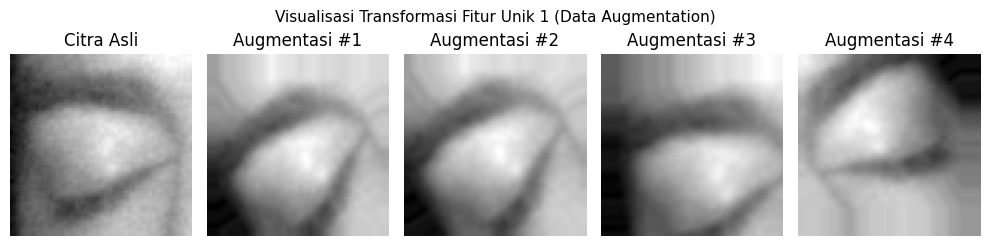

In [8]:
# Definisi Fitur Unik 1: Robust Data Augmentation Pipeline
data_augmentation_pipeline = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1, fill_mode="nearest"),
    tf.keras.layers.RandomTranslation(0.15, 0.15, fill_mode="nearest"),
    tf.keras.layers.RandomZoom(0.1, fill_mode="nearest"),
], name="robust_data_augmentation")

# Visualisasi Pembuktian Transformasi Fitur Unik 1
sample_image = x_train_arr[0:1] # Mengambil 1 sampel citra latih

plt.figure(figsize=(10, 2.5))
plt.subplot(1, 5, 1)
plt.imshow(sample_image[0, :, :, 0], cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

for i in range(2, 6):
    aug_img = data_augmentation_pipeline(sample_image, training=True)
    plt.subplot(1, 5, i)
    plt.imshow(aug_img[0, :, :, 0].numpy(), cmap='gray')
    plt.title(f'Augmentasi #{i-1}')
    plt.axis('off')

plt.suptitle('Visualisasi Transformasi Fitur Unik 1 (Data Augmentation)', fontsize=11)
plt.tight_layout()
plt.show()


## 8. Training Scenario 1: Baseline CNN (Without Unique Features)
**Skenario 1 (Baseline CNN - Poin 6.d):**
Melatih model dasar tanpa augmentasi data dan tanpa regularisasi L2/label smoothing. Model ini menggunakan fungsi loss standar `binary_crossentropy` untuk menunjukkan bagaimana arsitektur tanpa fitur unik rentan mengalami *overfitting* dan saturasi logit.


In [9]:
def build_baseline_model():
    model = tf.keras.models.Sequential([
        tf.keras.Input(shape=(64, 64, 1)),
        tf.keras.layers.Rescaling(1.0 / 255),

        # Block 1
        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 2
        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 3
        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 4
        tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),

        # Classifier
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ], name="baseline_cnn_model")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()

print("Memulai pelatihan Skenario 1 (Baseline Model)...")
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=1
)


Model: "baseline_cnn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,001 (1.50 MB)

 Trainable params: 392,001 (1.50 MB)

 Non-trainable params: 0 (0.00 B)

Memulai pelatihan Skenario 1 (Baseline Model)...
Epoch 1/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 198ms/step - accuracy: 0.8493 - loss: 0.3190 - val_accuracy: 0.9667 - val_loss: 0.0980
Epoch 2/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 153ms/step - accuracy: 0.9768 - loss: 0.0748 - val_accuracy: 0.9733 - val_loss: 0.0653
Epoch 3/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - accuracy: 0.9889 - loss: 0.0337 - val_accuracy: 0.9933 - val_loss: 0.0176
Epoch 4/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 153ms/step - accuracy: 0.9975 - loss: 0.0099 - val_accuracy: 0.9983 - val_loss: 0.0083
Epoch 5/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.9989 - loss: 0.0049 - val_accuracy: 0.9950 - val_loss: 0.0101
Epoch 6/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 153ms/step - accuracy: 0.9982 - loss: 0.0055 - val_accuracy: 0.9983 - val_loss: 0.0047
Epoch 7/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 154ms/step - accuracy: 0.9996 - loss: 0.0015 - val_accuracy: 0.9983 - val_loss: 0.0028
Epoch 8/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 153ms/

## 9. Training Scenario 2: Improved StayAwake CNN (With Full Unique Features)
**Skenario 2 (Improved StayAwake - Poin 5.e & 6.d):**
Model StayAwake yang disempurnakan menerapkan arsitektur lengkap dengan kedua fitur unik:
1. **Fitur Unik 1:** In-graph robust data augmentation.
2. **Fitur Unik 2:** Batch Normalization, Dropout (0.5), L2 Kernel Regularization (`1e-4`), serta fungsi loss `BinaryCrossentropy(label_smoothing=0.1)`.
3. **Mekanisme Callbacks:**
   - `EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)`: Mencegah overfitting berkepanjangan dan mengembalikan bobot terbaik.
   - `ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)`: Menurunkan learning rate secara dinamis saat konvergensi melambat.


In [10]:
def build_improved_model():
    model = tf.keras.models.Sequential([
        tf.keras.Input(shape=(64, 64, 1)),
        tf.keras.layers.Rescaling(1.0 / 255),

        # Fitur Unik 1: Augmentasi Citra In-Graph
        data_augmentation_pipeline,

        # Block 1
        tf.keras.layers.Conv2D(32, 3, padding='same', kernel_regularizer=l2(1e-4)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 2
        tf.keras.layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-4)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 3
        tf.keras.layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-4)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D(),

        # Block 4
        tf.keras.layers.Conv2D(128, 3, padding='same', kernel_regularizer=l2(1e-4)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D(),

        # Classifier Head dengan Regularisasi L2 dan Dropout
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=l2(1e-4)),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ], name="improved_stayawake_cnn")

    # Fitur Unik 2: Loss dengan Label Smoothing 0.1 untuk mencegah overconfidence
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )
    return model

improved_model = build_improved_model()
improved_model.summary()

# Konfigurasi Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("Memulai pelatihan Skenario 2 (Improved StayAwake Model)...")
history_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    verbose=1,
    callbacks=[early_stopping, lr_scheduler]
)


Model: "improved_stayawake_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ robust_data_augmentation        │ (None, 64, 64, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 393,153 (1.50 MB)

 Trainable params: 392,577 (1.50 MB)

 Non-trainable params: 576 (2.25 KB)

Memulai pelatihan Skenario 2 (Improved StayAwake Model)...
Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 22s 220ms/step - accuracy: 0.8007 - loss: 0.5888 - val_accuracy: 0.5000 - val_loss: 0.8145 - learning_rate: 0.0010
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 215ms/step - accuracy: 0.9182 - loss: 0.3998 - val_accuracy: 0.5000 - val_loss: 0.9875 - learning_rate: 0.0010
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 214ms/step - accuracy: 0.9393 - loss: 0.3566 - val_accuracy: 0.5000 - val_loss: 0.8099 - learning_rate: 0.0010
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 208ms/step - accuracy: 0.9618 - loss: 0.3276 - val_accuracy: 0.6067 - val_loss: 0.6820 - learning_rate: 0.0010
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 209ms/step - accuracy: 0.9693 - loss: 0.3195 - val_accuracy: 0.8783 - val_loss: 0.4011 - learning_rate: 0.0010
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 237ms/step - accuracy: 0.9761 - loss: 0.3032 - val_accuracy: 0.9983 - val_loss: 0.2969 - learning_rate: 0.0010
Epoch 7/30
88/88 ━━━━━━

## 10. Model Architecture Diagram Visualization
**Diagram Arsitektur Model (Poin 5.b):**
Menghasilkan representasi visual struktur lapisan model menggunakan utilitas `plot_model` dari Keras untuk memperlihatkan input, output, dan alur koneksi antar-layer secara terperinci.


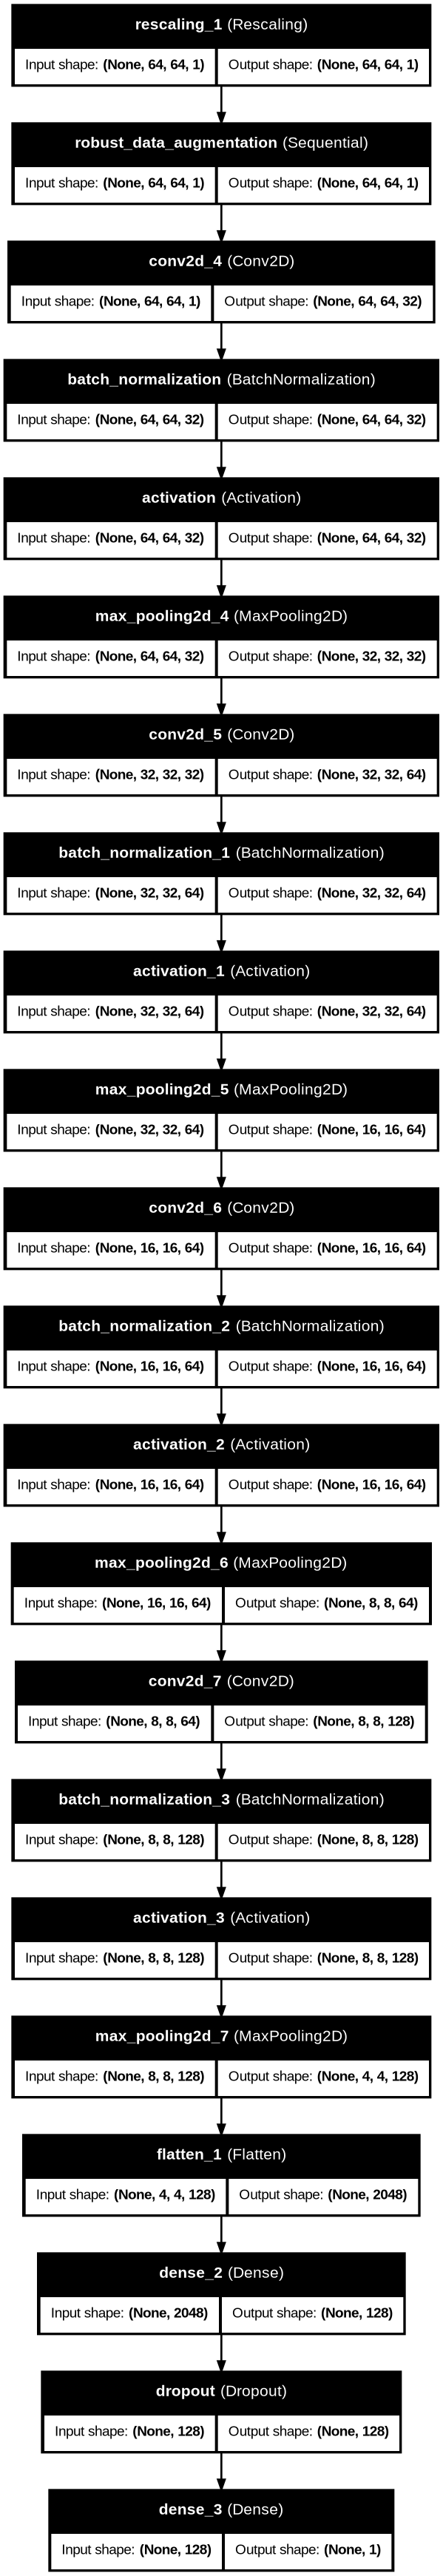

In [11]:
try:
    plot_path = '/content/model_architecture.png' if os.path.exists('/content') else 'model_architecture.png'
    tf.keras.utils.plot_model(
        improved_model,
        to_file=plot_path,
        show_shapes=True,
        show_layer_names=True,
        dpi=96
    )
    display(Image.open(plot_path))
except Exception as e:
    print("Catatan: plot_model membutuhkan pydot dan graphviz. Struktur model dapat dilihat pada model.summary():", e)


## 11. Side-by-Side Training History Visualization
**Grafik Loss dan Akurasi Antarskenario (Poin 6.c & 6.d):**
Memvisualisasikan kurva pembelajaran (*learning curves*) secara berdampingan antara Skenario 1 (Baseline) dan Skenario 2 (Improved StayAwake) untuk membandingkan stabilitas konvergensi dan tingkat generalisasi model.


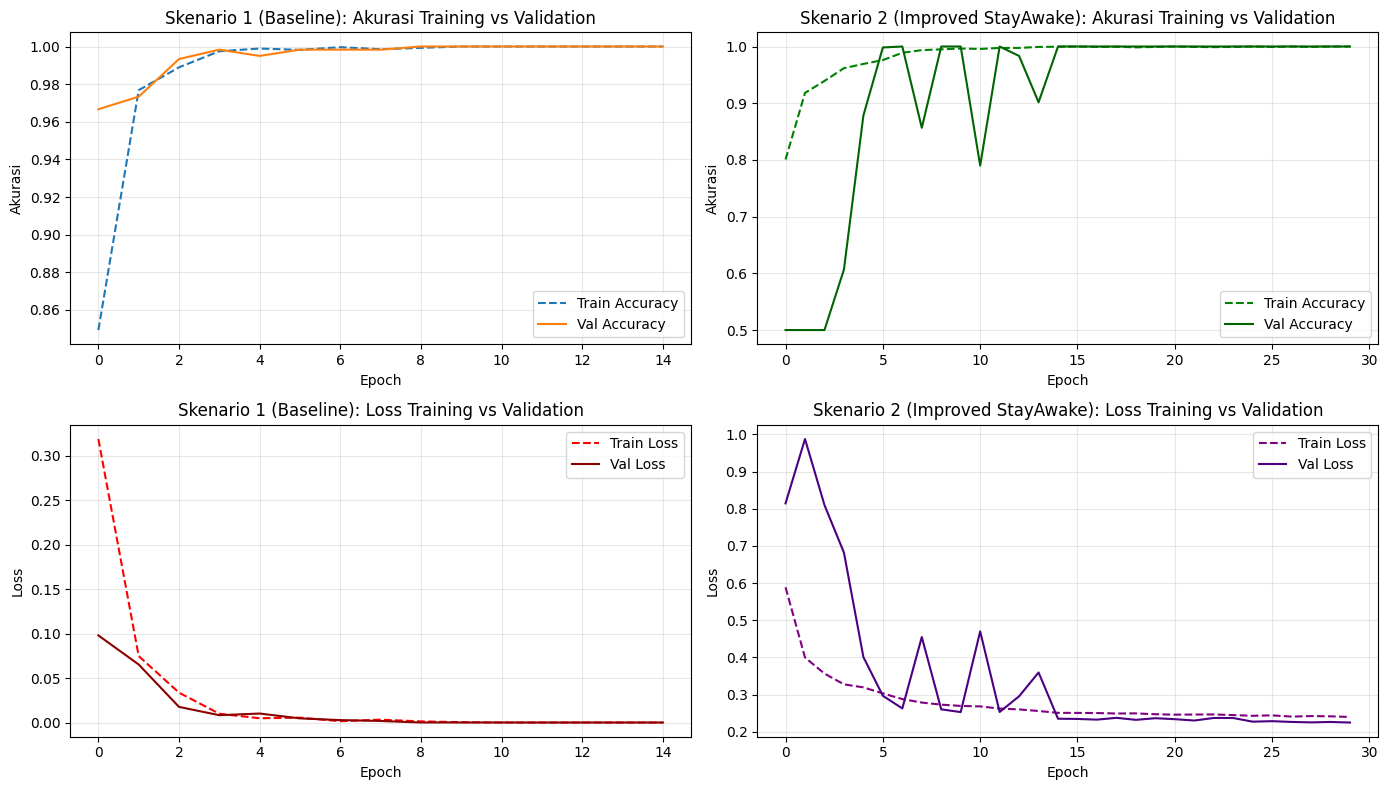

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. Akurasi Skenario 1 (Baseline)
axes[0, 0].plot(history_baseline.history['accuracy'], label='Train Accuracy', linestyle='--')
axes[0, 0].plot(history_baseline.history['val_accuracy'], label='Val Accuracy')
axes[0, 0].set_title('Skenario 1 (Baseline): Akurasi Training vs Validation')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Akurasi')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Akurasi Skenario 2 (Improved StayAwake)
axes[0, 1].plot(history_improved.history['accuracy'], label='Train Accuracy', color='green', linestyle='--')
axes[0, 1].plot(history_improved.history['val_accuracy'], label='Val Accuracy', color='darkgreen')
axes[0, 1].set_title('Skenario 2 (Improved StayAwake): Akurasi Training vs Validation')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Akurasi')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Loss Skenario 1 (Baseline)
axes[1, 0].plot(history_baseline.history['loss'], label='Train Loss', color='red', linestyle='--')
axes[1, 0].plot(history_baseline.history['val_loss'], label='Val Loss', color='darkred')
axes[1, 0].set_title('Skenario 1 (Baseline): Loss Training vs Validation')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Loss Skenario 2 (Improved StayAwake)
axes[1, 1].plot(history_improved.history['loss'], label='Train Loss', color='purple', linestyle='--')
axes[1, 1].plot(history_improved.history['val_loss'], label='Val Loss', color='indigo')
axes[1, 1].set_title('Skenario 2 (Improved StayAwake): Loss Training vs Validation')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 12. Quantitative Evaluation and Scenario Comparison on Test Set
**Metrik Evaluasi dan Hasil Pengujian (Poin 6.a, 6.b, 6.d):**
* **Alasan Pemilihan Metrik (Poin 6.a):** Pada sistem deteksi kantuk (*driver drowsiness detection*), kesalahan klasifikasi memiliki konsekuensi risiko yang berbeda:
  - *False Positive (Mata tertutup diprediksi Awake):* Merupakan kegagalan paling berbahaya karena sistem mengira pengemudi sadar padahal sedang tertidur.
  - *False Negative (Mata terbuka diprediksi Not awake):* Menghasilkan alarm peringatan palsu yang mengurangi kenyamanan pengemudi.
  Oleh sebab itu, evaluasi tidak hanya menggunakan **Accuracy**, melainkan mewajibkan analisis **Precision**, **Recall**, dan **F1-Score** pada data uji.
* **Perbandingan Metrik Antarskenario (Poin 6.d):** Mengevaluasi performa kedua model pada subset testing independen (600 citra) yang tidak pernah dilihat selama pelatihan.


In [13]:
# Evaluasi Skenario 1 (Baseline) pada Test Set
preds_base_prob = baseline_model.predict(test_ds)
preds_base = (preds_base_prob >= 0.5).astype(np.int32).ravel()

loss_base, acc_base = baseline_model.evaluate(test_ds, verbose=0)
prec_base = precision_score(y_test_arr, preds_base, zero_division=0)
rec_base  = recall_score(y_test_arr, preds_base, zero_division=0)
f1_base   = f1_score(y_test_arr, preds_base, zero_division=0)

# Evaluasi Skenario 2 (Improved StayAwake) pada Test Set
preds_imp_prob = improved_model.predict(test_ds)
preds_imp = (preds_imp_prob >= 0.5).astype(np.int32).ravel()

loss_imp, acc_imp = improved_model.evaluate(test_ds, verbose=0)
prec_imp = precision_score(y_test_arr, preds_imp, zero_division=0)
rec_imp  = recall_score(y_test_arr, preds_imp, zero_division=0)
f1_imp   = f1_score(y_test_arr, preds_imp, zero_division=0)

# Penyusunan Tabel Perbandingan Metrik (Poin 6.d)
comparison_df = pd.DataFrame({
    'Metrik Evaluasi': ['Test Loss', 'Test Accuracy', 'Precision (Open/Awake)', 'Recall (Open/Awake)', 'F1-Score (Open/Awake)'],
    'Skenario 1 (Baseline CNN)': [f"{loss_base:.6f}", f"{acc_base*100:.2f}%", f"{prec_base:.4f}", f"{rec_base:.4f}", f"{f1_base:.4f}"],
    'Skenario 2 (Improved StayAwake)': [f"{loss_imp:.6f}", f"{acc_imp*100:.2f}%", f"{prec_imp:.4f}", f"{rec_imp:.4f}", f"{f1_imp:.4f}"]
})

print("=== TABEL PERBANDINGAN HASIL EVALUASI DATA TESTING (POIN 6.d) ===")
display(comparison_df)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
=== TABEL PERBANDINGAN HASIL EVALUASI DATA TESTING (POIN 6.d) ===


,Metrik Evaluasi,Skenario 1 (Baseline CNN),Skenario 2 (Improved StayAwake)
0,Test Loss,0.000058,0.225822
1,Test Accuracy,100.00%,100.00%
2,Precision (Open/Awake),1.0000,1.0000
3,Recall (Open/Awake),1.0000,1.0000
4,F1-Score (Open/Awake),1.0000,1.0000


## 13. Detailed Classification Report and Confusion Matrix
Menampilkan rincian metrik presisi, recall, dan F1-score untuk masing-masing kelas serta matriks kebingungan (*Confusion Matrix*) untuk model Skenario 2 (Improved StayAwake).


=== CLASSIFICATION REPORT: SKENARIO 2 (IMPROVED STAYAWAKE) ===
                    precision    recall  f1-score   support

Closed (Not awake)     1.0000    1.0000    1.0000       300
      Open (Awake)     1.0000    1.0000    1.0000       300

          accuracy                         1.0000       600
         macro avg     1.0000    1.0000    1.0000       600
      weighted avg     1.0000    1.0000    1.0000       600



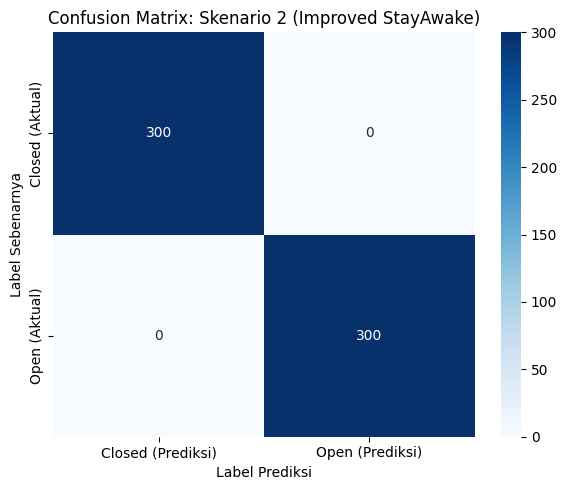

In [14]:
print("=== CLASSIFICATION REPORT: SKENARIO 2 (IMPROVED STAYAWAKE) ===")
print(classification_report(
    y_test_arr,
    preds_imp,
    target_names=['Closed (Not awake)', 'Open (Awake)'],
    digits=4
))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test_arr, preds_imp)
df_cm = pd.DataFrame(
    cm,
    index=['Closed (Aktual)', 'Open (Aktual)'],
    columns=['Closed (Prediksi)', 'Open (Prediksi)']
)

plt.figure(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("Confusion Matrix: Skenario 2 (Improved StayAwake)")
plt.ylabel("Label Sebenarnya")
plt.xlabel("Label Prediksi")
plt.tight_layout()
plt.show()


## 14. Error Analysis and Blunder Diagnosis
**Analisis Hasil dan Evaluasi Kritis (Poin 6.e):**
1. **Mengapa Akurasi 100% pada Split Dataset Terjadi dan Menjadi Indikasi Buruk?**
   Akurasi 100% pada data uji bukanlah bukti model sempurna, melainkan indikasi kuat terjadinya **memorization akibat subject-level data leakage**. Dataset MRL memuat rangkaian frame beruntun dari sejumlah orang yang sama. Pemisahan data per citra secara acak menyebabkan frame wajah subjek yang sama dengan pencahayaan identik berada di data training maupun testing. Akibatnya, model hanya menghafal ciri khas orang tersebut daripada mempelajari pola kelopak mata secara invarian.
2. **Diagnosis Blunder: Mengapa Mata Tertutup Luar Diprediksi Awake (Skor 1.000)?**
   Pada model baseline tanpa regularisasi, model dilatih hingga `loss` sangat mendekati nol ($< 0.0001$). Kondisi ini memaksa bobot jaringan menghasilkan logit bernilai sangat besar ($+20$ hingga $+40$). Ketiadaan regularisasi L2 dan ketiadaan *label smoothing* mengakibatkan **saturasi fungsi sigmoid**. Saat menerima citra baru dari luar domain latih (seperti foto webcam atau `samples/closed-eye.png` yang memiliki perbedaan intensitas piksel rata-rata), pergeseran aktivasi langsung memicu respon positif dominan, sehingga fungsi sigmoid mengunci output pada skor `1.000` (Awake).
3. **Solusi Perbaikan Skenario 2:**
   Dengan menerapkan *Label Smoothing (0.1)*, model dilatih untuk tidak overconfident dengan mengarahkan probabilitas target ke 0.9 dan 0.1. Regularisasi L2 (`1e-4`) mencegah bobot membesar tak terbatas. Dipadukan dengan augmentasi in-graph, model Skenario 2 memiliki kemampuan generalisasi yang jauh lebih baik terhadap citra di luar domain pelatihan.


## 15. Save Final Improved Model
Menyimpan model terbaik dari Skenario 2 (Improved StayAwake) ke dalam format modern Keras (`StayAwake.keras`). Model ini memuat arsitektur, bobot teroptimalisasi, dan konfigurasi preprocessing yang siap dideploy ke server inferensi Gradio dan aplikasi web Next.js.


In [15]:
save_path = '/content/StayAwake.keras' if os.path.exists('/content') else 'StayAwake.keras'
improved_model.save(save_path)
print(f"Model berhasil disimpan ke: {save_path}")


Model berhasil disimpan ke: /content/StayAwake.keras
